# Forecast a time series with Timestral-209M

This notebook forecasts generated power from `data/spg.csv` using Timestral-209M and plots the median with an 80% prediction interval. No training is needed.

**Data:** `data/spg.csv` contains 4,213 rows. We forecast `generated_power_kw` using historical power plus six weather and solar-angle covariates. No future weather is supplied to the operational forecast. Historical features are assumed available at the forecast cutoff; the CSV does not document their issue times. The file has no timestamps, so we preserve row order and use a zero-based observation index. This assumes the rows are chronologically ordered and represent consistent sampling steps. The forecast horizon is measured in rows, not hours or days; timestamps are needed to verify timing and identify missing time steps.

This project uses Python 3.12, managed by uv. The first run needs internet access to install dependencies and download the model (about 837 MB of weights); later runs reuse the Hugging Face cache. CPU inference is supported; a CUDA GPU is used when available.

References: [model card](https://huggingface.co/mistralai/Timestral-209M) and [official inference library](https://github.com/mistralai/timestral).

## Environment setup (run in a terminal)

From the project directory, install the dependencies and launch Jupyter with uv:

```sh
uv sync
uv run jupyter lab timestral_forecast.ipynb
```

Select the Python kernel from this project's `.venv`. In VS Code, choose `.venv/bin/python` in the notebook kernel picker. Dependencies are declared in `pyproject.toml`; use `uv add PACKAGE` to add a package. The notebook itself does not install packages.


## 1. Load generated power

Run the notebook from the project directory. `CSV_PATH` selects the supplied dataset, `VALUE_COLUMN` selects the target, and `PREDICTION_LENGTH` controls the number of future rows (30 by default).

The observations retain their CSV order. Empty target cells remain missing (`NaN`), which Timestral supports. Invalid numeric text and infinite values are rejected. No dates or sampling frequency are invented.

In [25]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from timestral import TimestralForecaster
from scripts.benchmark_forecasts import CORE_COLUMNS, EXPANDED_COLUMNS

torch.set_num_threads(4)

CSV_PATH = Path("data/spg.csv")
VALUE_COLUMN = "generated_power_kw"
PREDICTION_LENGTH = 30
MODEL_ID = "mistralai/Timestral-209M"
COVARIATE_COLUMNS = CORE_COLUMNS  # Also compare EXPANDED_COLUMNS in section 5.

if not isinstance(PREDICTION_LENGTH, int) or not 1 <= PREDICTION_LENGTH <= 1024:
    raise ValueError("Choose an integer forecast horizon between 1 and 1024.")

In [26]:
data = pd.read_csv(CSV_PATH)
values = pd.to_numeric(data[VALUE_COLUMN], errors="raise")
series = pd.Series(
    values.to_numpy(dtype=float),
    index=pd.RangeIndex(len(data), name="observation"),
    name=VALUE_COLUMN,
)
if np.isinf(series.to_numpy()).any():
    raise ValueError("Replace infinite values with valid observations or empty cells.")
if series.notna().sum() < 3:
    raise ValueError("Provide at least three non-missing observations.")
print(f"Loaded {len(series):,} observations from {CSV_PATH}; missing={series.isna().sum():,}")
display(series.tail().to_frame())

covariates = data[COVARIATE_COLUMNS].apply(pd.to_numeric, errors="raise")
if np.isinf(covariates.to_numpy()).any():
    raise ValueError("Covariates contain infinite values.")
print("Historical covariates:", COVARIATE_COLUMNS)

Loaded 4,213 observations from data/spg.csv; missing=0


,generated_power_kw
observation,
4208,173.410560
4209,403.792220
4210,158.367780
4211,126.953060
4212,20.055031


Historical covariates: ['shortwave_radiation_backwards_sfc', 'total_cloud_cover_sfc', 'temperature_2_m_above_gnd', 'relative_humidity_2_m_above_gnd', 'zenith', 'azimuth']


### Actual generated power

The first panel shows all observed power values; the second makes the latest 180 observations easier to inspect. Both show measurements from the CSV, in kW. The index preserves file order.

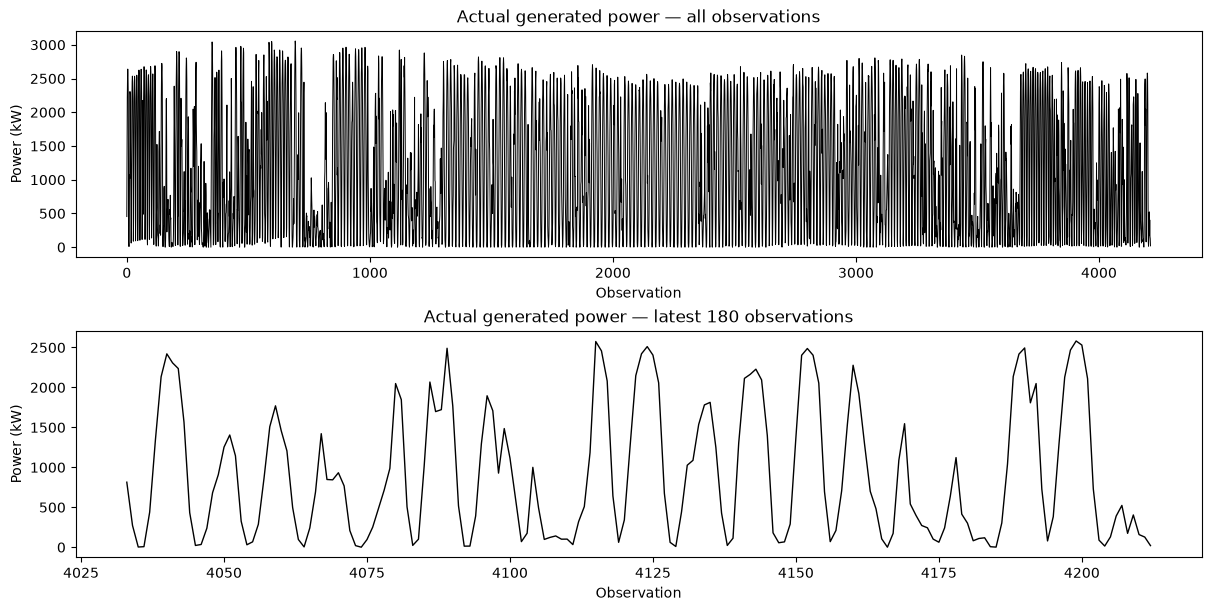

In [27]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6), constrained_layout=True)
axes[0].plot(series.index, series, color="black", linewidth=0.7)
axes[0].set(title="Actual generated power — all observations", xlabel="Observation", ylabel="Power (kW)")
axes[1].plot(series.iloc[-180:].index, series.iloc[-180:], color="black", linewidth=1)
axes[1].set(title="Actual generated power — latest 180 observations", xlabel="Observation", ylabel="Power (kW)")
plt.show()

## 2. Load Timestral and forecast

The model receives the latest 32,768 time steps at most. Forecasts use only historical values. Target shape is `(1, 1, T)`; past covariates have shape `(1, C, T)` and are aligned to exactly the same rows. The library normalizes them internally. We explicitly use input shape `(series, variables, time) = (1, 1, T)` and select the single series and variable from the output.

The 10th and 90th quantiles form a nominal 80% prediction interval. This describes model uncertainty; actual coverage on your data may differ. The final section checks three held-out windows before interpreting the future forecast. Timestral handles normalization and inverse scaling internally; input and output remain in kW. The library enables symmetric averaging and non-negative clipping by default.

In [28]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Loading {MODEL_ID} on {device}...")
model = TimestralForecaster.from_pretrained(MODEL_ID, device=device)

context = series.iloc[-32768:].to_numpy(dtype=np.float32)[None, None, :]
if np.isfinite(context).sum() < 3:
    raise ValueError("The latest context must contain at least three valid observations.")
with torch.inference_mode():
    prediction = model.forecast(
        context, prediction_length=PREDICTION_LENGTH,
        past_covariates=covariates.iloc[-32768:].to_numpy(dtype=np.float32).T[None],
    )

# Handle either NumPy arrays or tensors, including tensors on a GPU.
def single_forecast(values):
    if isinstance(values, torch.Tensor):
        values = values.detach().cpu().numpy()
    return np.asarray(values)[0, 0, :]

future_index = pd.RangeIndex(len(series), len(series) + PREDICTION_LENGTH, name="observation")
forecast = pd.DataFrame(
    {
        "median": single_forecast(prediction.median),
        "p10": single_forecast(prediction.quantile(0.1)),
        "p90": single_forecast(prediction.quantile(0.9)),
    },
    index=future_index,
)
display(forecast.head())

Loading mistralai/Timestral-209M on cpu...


Fetching 2 files: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 2/2 [00:00<00:00, 513.10it/s]


,median,p10,p90
observation,,,
4213,57.235229,14.726990,216.966217
4214,311.995636,69.385315,1086.620850
4215,774.088379,146.510345,1814.548584
4216,1018.297119,211.177582,2252.371826
4217,1098.385620,209.458649,2455.127686


## 3. Plot and save

The plot shows recent generated power alongside the forecast. The exported CSV contains the future observation index, median, and interval bounds in kW. No additional postprocessing is applied; the library itself clips forecasts to zero when the historical target is non-negative. Running this cell again replaces `forecast.csv`.

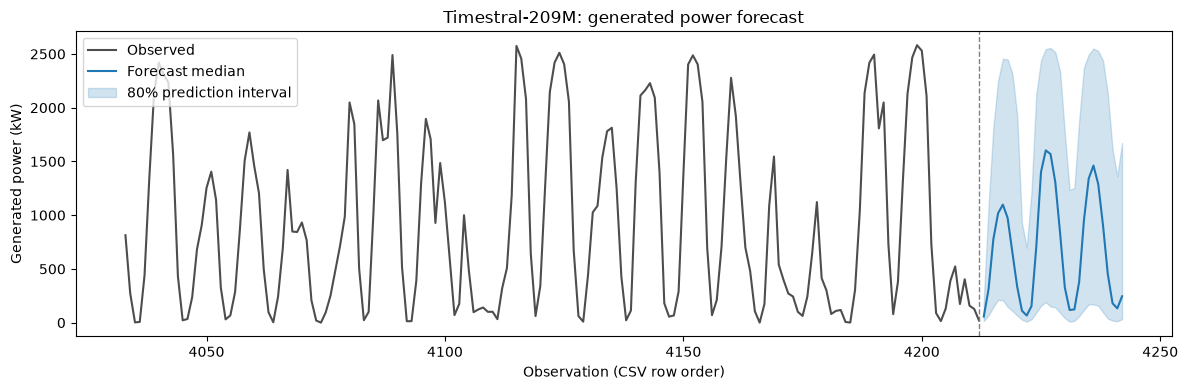

Saved forecast.csv


In [29]:
fig, ax = plt.subplots(figsize=(12, 4))
series.iloc[-180:].plot(ax=ax, color="0.3", label="Observed")
ax.plot(forecast.index, forecast["median"], color="tab:blue", label="Forecast median")
ax.fill_between(
    forecast.index, forecast["p10"], forecast["p90"],
    color="tab:blue", alpha=0.2, label="80% prediction interval",
)
ax.axvline(series.index[-1], color="0.5", linestyle="--", linewidth=1)
ax.set(title="Timestral-209M: generated power forecast", xlabel="Observation (CSV row order)", ylabel="Generated power (kW)")
ax.legend()
fig.tight_layout()
plt.show()

forecast.to_csv("forecast.csv")
print("Saved forecast.csv")

## 4. Check the observation spacing

Large backward jumps in solar azimuth suggest cycle boundaries; the number of observations between them varies. These are inferred cycles, not reconstructed dates. Original timestamps are needed to establish the time grid. The horizon remains measured in rows.

Median forecasts need not reproduce sunny-day peaks. Evaluate accuracy against withheld observations, including the interval coverage, rather than judging the smoothness of the plotted forecast.

In [30]:
azimuth = pd.to_numeric(data["azimuth"], errors="raise").to_numpy()
cycle_starts = np.flatnonzero(np.diff(azimuth) < -50) + 1
cycle_lengths = pd.Series(np.diff(cycle_starts), name="rows_per_inferred_cycle")
display(cycle_lengths.value_counts().sort_index().rename("count").to_frame())
print("Recent inferred cycle lengths:", cycle_lengths.tail(20).tolist())

,count
rows_per_inferred_cycle,
5,1
6,4
7,3
8,5
9,37
10,78
11,30
12,35
13,70


Recent inferred cycle lengths: [10, 9, 10, 9, 9, 10, 10, 9, 10, 8, 9, 9, 10, 9, 9, 9, 10, 9, 10, 9]


## 5. Compare models on rolling holdouts

The reproducible benchmark uses 12 equally spaced cutoffs across the latter half of the file, with non-overlapping 30-row holdouts. All models use the same cutoffs; horizons 1 and 9 are the first 1 and 9 predictions of each 30-row forecast. MAE and RMSE pool errors across origins. These are exploratory results, not an untouched test set or a guarantee of future performance.

- **Timestral:** target only, six core past covariates, and ten expanded past covariates (adding incidence angle and three cloud layers). All historical rows are available, up to the model's context limit.
- **Gradient Boosting:** a direct forecast using 24 target lags, weather lags 1/2/3/9, target means, and forecast lead. Each fit uses only training examples whose entire 30-row target window precedes the cutoff. It compresses history into features; both models have access only to information before the cutoff. Fixed settings use absolute-error loss, 100 iterations, and 15 leaves, with no random validation split or hyperparameter tuning.
- **Baselines:** last value and repetition of the last nine rows. Nine rows is a heuristic, not a verified daily cycle.
- **Idealized future inputs:** an optional, separate Timestral experiment uses actual weather/angles from held-out rows. This is retrospective conditional prediction, not an operational forecast. Real deployment requires inputs available in advance.

The six core features remain the notebook default from the earlier experiment; compare the expanded set before changing it. Published random-split regression scores are not directly comparable. See the [example notebook](https://github.com/MariaPinto85/Solar-Energy-Power-Generation/blob/main/Solar%20Energy%20Forcasting.ipynb) and [Timestral covariate documentation](https://github.com/mistralai/timestral#covariates).

To refresh the saved evaluation, set `RUN_BENCHMARK = True` below, or run `uv run python scripts/benchmark_forecasts.py --include-oracle` in a terminal. This takes a few minutes on CPU and replaces files in `reports/rolling/`.

Horizon (rows): MAE in kW,1,9,30
model,,,
Gradient Boosting expanded past,265.9,515.0,663.2
Last value,478.4,933.2,871.4
Repeat last 9 rows,744.4,1041.9,1048.5
Timestral core past,225.5,250.7,349.9
Timestral expanded past,222.9,276.3,357.5
Timestral target only,209.1,340.5,412.7


,model,horizon,rmse_kw,coverage_80
0,Gradient Boosting expanded past,1,348.251,NaN
1,Last value,1,586.797,NaN
2,Repeat last 9 rows,1,967.735,NaN
3,Timestral core past,1,462.367,0.833
4,Timestral expanded past,1,438.649,0.750
5,Timestral target only,1,346.150,0.833
7,Gradient Boosting expanded past,9,688.323,NaN
8,Last value,9,1126.803,NaN
9,Repeat last 9 rows,9,1285.309,NaN
10,Timestral core past,9,443.769,0.898


IDEALIZED: includes actual future weather/angles, not a deployable forecast


,scenario,model,mae_kw,coverage_80,n_predictions,rmse_kw,horizon
6,idealized future inputs,Timestral expanded known,210.839,0.917,12,382.820,1
13,idealized future inputs,Timestral expanded known,172.017,0.889,108,277.697,9
20,idealized future inputs,Timestral expanded known,227.820,0.814,360,371.806,30


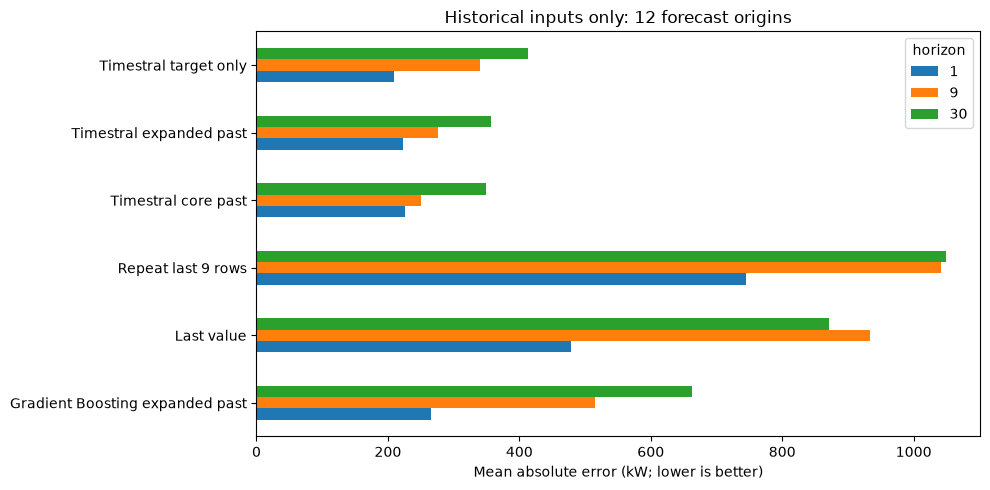

In [31]:
import hashlib
import json
import subprocess
import sys

RUN_BENCHMARK = False
report_dir = Path("reports/rolling")
if RUN_BENCHMARK:
    subprocess.run([sys.executable, "scripts/benchmark_forecasts.py", "--include-oracle"], check=True)

if not (report_dir / "metrics.csv").exists():
    raise FileNotFoundError("Run the benchmark first (set RUN_BENCHMARK = True).")
protocol = json.loads((report_dir / "protocol.json").read_text())
if protocol["data_sha256"] != hashlib.sha256(CSV_PATH.read_bytes()).hexdigest():
    raise ValueError("Saved evaluation used different data. Rerun the benchmark.")
metrics = pd.read_csv(report_dir / "metrics.csv")
operational = metrics[metrics.scenario == "historical only"]
display(operational.pivot(index="model", columns="horizon", values="mae_kw").round(1).rename_axis(columns="Horizon (rows): MAE in kW"))
display(operational[["model", "horizon", "rmse_kw", "coverage_80"]].round(3))
idealized = metrics[metrics.scenario != "historical only"]
if len(idealized):
    print("IDEALIZED: includes actual future weather/angles, not a deployable forecast")
    display(idealized.round(3))

ax = operational.pivot(index="model", columns="horizon", values="mae_kw").plot.barh(figsize=(10, 5))
ax.set(xlabel="Mean absolute error (kW; lower is better)", ylabel="", title="Historical inputs only: 12 forecast origins")
plt.tight_layout()
plt.show()

## 6. Add TimesFM-3

[TimesFM-3](https://github.com/google-research/timesfm) natively supports historical covariates. The optional script evaluates power-only, core-past, and expanded-past variants at the **same origins and horizons** as section 5. It also forecasts the next 30 rows with the six core historical covariates. Input series are 1D arrays; historical covariates are `(channels, time)`. Output deciles are 0.1 through 0.9: indices 0/4/8 provide p10/median/p90. The official evaluator defaults enable symmetric averaging, non-negativity and quantile sorting, without additional z-normalization.

Run `uv run --script scripts/evaluate_timesfm.py` from the project directory, or set `RUN_TIMESFM = True` below. This uses an isolated uv-managed environment with `timesfm[torch]==3.0.2`, keeping the Timestral project's lockfile independent. The first run downloads the package and `google/timesfm-3.0-pytorch` weights. CPU is the default; add `--device cuda` in the terminal for a CUDA GPU.

The downloadable weights are restricted to **non-commercial, non-production use** under [Google's model license](https://huggingface.co/google/timesfm-3.0-pytorch). This integration has adapter tests; real TimesFM inference could not be executed in the authoring environment because package downloads were blocked. TimesFM scores appear only after a successful run.

horizon,1,9,30
model,,,
Gradient Boosting expanded past,265.9,515.0,663.2
Last value,478.4,933.2,871.4
Repeat last 9 rows,744.4,1041.9,1048.5
TimesFM-3 core past,196.6,377.4,459.9
TimesFM-3 expanded past,197.2,375.7,451.8
TimesFM-3 target only,183.2,409.8,517.2
Timestral core past,225.5,250.7,349.9
Timestral expanded past,222.9,276.3,357.5
Timestral target only,209.1,340.5,412.7


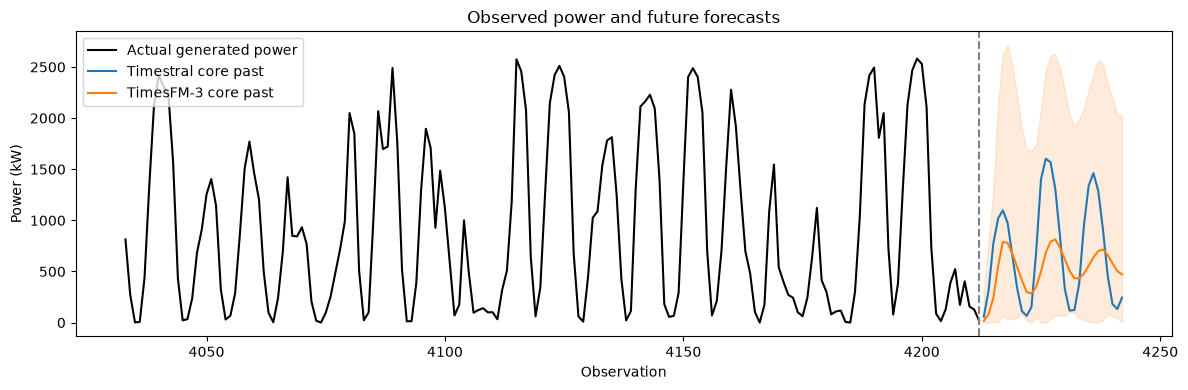

In [32]:
RUN_TIMESFM = False
if RUN_TIMESFM:
    subprocess.run(["uv", "run", "--script", "scripts/evaluate_timesfm.py"], check=True)

timesfm_dir = Path("reports/timesfm")
timesfm_predictions = None
if (timesfm_dir / "protocol.json").exists():
    timesfm_protocol = json.loads((timesfm_dir / "protocol.json").read_text())
    for key in ("data_sha256", "origins", "horizons", "core_columns", "expanded_columns"):
        if timesfm_protocol[key] != protocol[key]:
            raise ValueError(f"TimesFM comparison has a different {key}; rerun it.")
    timesfm_predictions = pd.read_csv(timesfm_dir / "predictions.csv")
    timesfm_metrics = pd.read_csv(timesfm_dir / "metrics.csv")
    combined_metrics = pd.concat([operational, timesfm_metrics], ignore_index=True)
    display(combined_metrics.pivot(index="model", columns="horizon", values="mae_kw").round(1))
    future_timesfm = pd.read_csv(timesfm_dir / "forecast.csv", index_col="observation")
    ax = series.iloc[-180:].plot(figsize=(12, 4), color="black", label="Actual generated power")
    ax.plot(forecast.index, forecast["median"], label="Timestral core past", color="tab:blue")
    ax.plot(future_timesfm.index, future_timesfm["median"], label="TimesFM-3 core past", color="tab:orange")
    ax.fill_between(future_timesfm.index, future_timesfm["p10"], future_timesfm["p90"], color="tab:orange", alpha=0.15)
    ax.axvline(series.index[-1], color="grey", linestyle="--")
    ax.set(title="Observed power and future forecasts", xlabel="Observation", ylabel="Power (kW)")
    ax.legend()
    plt.tight_layout()
    plt.show()
else:
    print("TimesFM-3 has not run yet. Run: uv run --script scripts/evaluate_timesfm.py")

## 7. Predictions versus actual power on held-out rows

These plots compare forecasts with the actual generated power in three recent benchmark windows. Black is observed power; the dashed line marks the forecast cutoff. TimesFM is added automatically after its evaluation finishes. Beyond the final row of the CSV, actual future power is unavailable, so only these held-out windows permit a direct accuracy comparison.

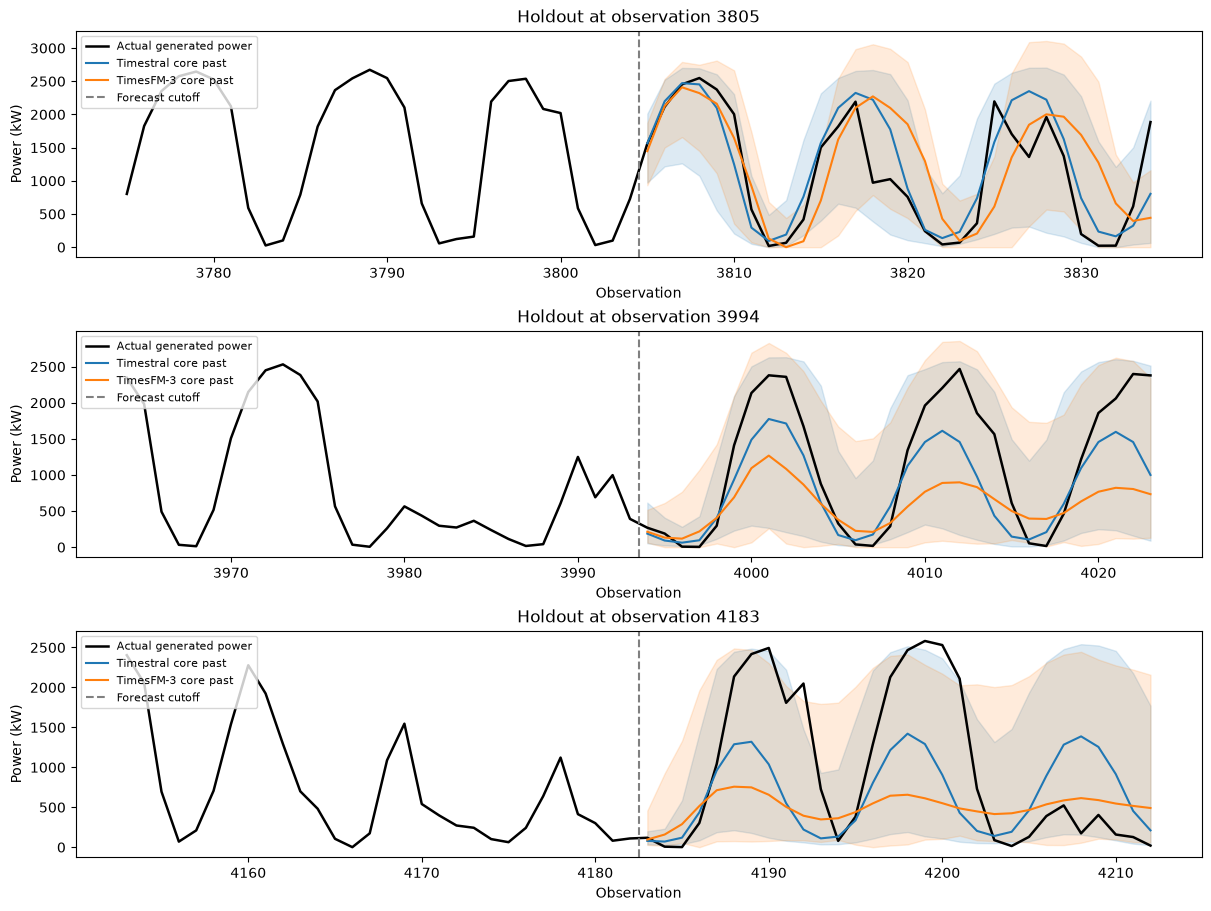

In [33]:
heldout = pd.read_csv(report_dir / "predictions.csv")
if timesfm_predictions is not None:
    heldout = pd.concat([heldout, timesfm_predictions], ignore_index=True)
fig, axes = plt.subplots(3, 1, figsize=(12, 9), constrained_layout=True)
model_colors = {"Timestral core past": "tab:blue", "TimesFM-3 core past": "tab:orange"}
for ax, origin in zip(axes, protocol["origins"][-3:]):
    actual_window = series.iloc[max(0, origin - 30):origin + 30]
    ax.plot(actual_window.index, actual_window, color="black", linewidth=1.8, label="Actual generated power")
    for name, color in model_colors.items():
        rows = heldout[(heldout.origin == origin) & (heldout.model == name)].sort_values("lead")
        if rows.empty:
            continue
        np.testing.assert_allclose(rows.actual, series.iloc[origin:origin+30], rtol=1e-5)
        ax.plot(rows.observation, rows.predicted, color=color, label=name)
        ax.fill_between(rows.observation, rows.p10, rows.p90, color=color, alpha=0.15)
    ax.axvline(origin - 0.5, color="grey", linestyle="--", label="Forecast cutoff")
    ax.set(title=f"Holdout at observation {origin}", xlabel="Observation", ylabel="Power (kW)")
    ax.legend(loc="upper left", fontsize=8)
plt.show()